## Table of Contents

#### Part I: Research Question

A1. [Research Question](#A1.-Research-Question)

A2. [Defined Goal](#A2.-Defined-Goal)

#### Part II: Method Justification

B1. [Summary of Assumptions](#B1.-Summary-of-Assumptions)

#### Part III: Data Preparation

C1. [Line Graph Visualization](#C1.-Line-Graph-Visualization)

C2. [Time Step Formating](#C2.-Time-Step-Formating)

C3. [Stationarity](#C3.-Stationarity)

C4. [Steps to Prepare the Data](#C4.-Steps-to-Prepare-the-Data)

C5. [Prepared Data Set](#C5.-Prepared-Data-Set)

#### Part IV: Model Identification and Analysis

D1. [Report Findings and Visualizations](#D1.-Report-Findings-and-Visualizations)

D2. [ARIMA Model](#D2.-ARIMA-Model)

D3. [Forecasting Using ARIMA Model](#D3.-Forecasting-Using-ARIMA-Model)

D4. [Output and Calculations](#D4.-Output-and-Calculations)

D5. [Code](#D5.-Code)

#### Part V: Data Summary and Implications

E1. [Results](#E1.-Results)

E2. [Annotated Visualization](#E2.-Annotated-Visualization)

E3. [Recommendation](#E3.-Recommendation)

#### Part VI: Reporting

F. [Reporting](#F.-Reporting)

G. [Sources of Third-Party Code](#G.-Sources-of-Third-Party-Code)

H. [Sources](#H.-Sources)

### Part I: Research Question

#### A1. Research Question

The research question for this assessment is: using the provided revenue data, can 180 days of revenue be forecasted using time series analysis?

#### A2. Defined Goal

The goal of this data analysis will be to implement an ARIMA model to forecast 180 days of revenue, using two years of revenue data provided in a time series dataset.

### Part II: Method Justification

#### B1. Summary of Assumptions

Time series models such as ARIMA rely on several assumptions regarding the nature of the data being analyzed. One of these assumptions is that the data being analyzed displays stationarity - that is, that the statistical features of the data, such as mean, variance, and autocorrelation, stay constant over time. Another way of describing stationarity is to say that the data shows consistency over time in relation to itself. Another assumption of all time series models is that behaviors displayed in previous data can be utilized to predict future behaviors; the very nature of time series modelling relies on the idea that the future can be predicted with some level of accuracy based on the past. (StatisticsSolutions, 2025)

### Part III: Data Preparation

#### C1. Line Graph Visualization

The initial code steps below import the time series data, assess its structure, format the index column to contain datetime data, and plot a line graph visualization of the data.

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime
from datetime import timedelta
from sklearn.model_selection import train_test_split
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
import pmdarima as pm

# Import time series data
teleco_input = pd.read_csv('data/teleco_time_series.csv')

# Inspect input file
print(teleco_input.info())
print(teleco_input.describe())
print(teleco_input.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Day      731 non-null    int64  
 1   Revenue  731 non-null    float64
dtypes: float64(1), int64(1)
memory usage: 11.6 KB
None
              Day     Revenue
count  731.000000  731.000000
mean   366.000000    9.822901
std    211.165812    3.852645
min      1.000000    0.000000
25%    183.500000    6.872836
50%    366.000000   10.785571
75%    548.500000   12.566911
max    731.000000   18.154769
   Day   Revenue
0    1  0.000000
1    2  0.000793
2    3  0.825542
3    4  0.320332
4    5  1.082554


In [2]:
# Convert days to dates
# Assume start date of 1/1/2020 for purpose of exercise
def day_date_cov(day_num):
    start_date = datetime.date(2020,1,1)
    new_date = start_date + timedelta(days=day_num-1)
    return new_date.strftime("%m/%d/%Y")

teleco_input['Date'] = teleco_input['Day'].apply(day_date_cov)

# Convert new Date column to datetime dtype
teleco_input['Date'] = pd.to_datetime(teleco_input['Date'])

# Set DF index to Date
# Drop Day column as this is no longer required
teleco_input = teleco_input.set_index('Date')
teleco_input = teleco_input.drop('Day',axis=1)

# Place into new dataset for use in analysis
teleco_timeseries = teleco_input

# Print summary to verify data transformation
print(teleco_timeseries.info())
print(teleco_timeseries.describe())
print(teleco_timeseries.head())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 731 entries, 2020-01-01 to 2021-12-31
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Revenue  731 non-null    float64
dtypes: float64(1)
memory usage: 11.4 KB
None
          Revenue
count  731.000000
mean     9.822901
std      3.852645
min      0.000000
25%      6.872836
50%     10.785571
75%     12.566911
max     18.154769
             Revenue
Date                
2020-01-01  0.000000
2020-01-02  0.000793
2020-01-03  0.825542
2020-01-04  0.320332
2020-01-05  1.082554


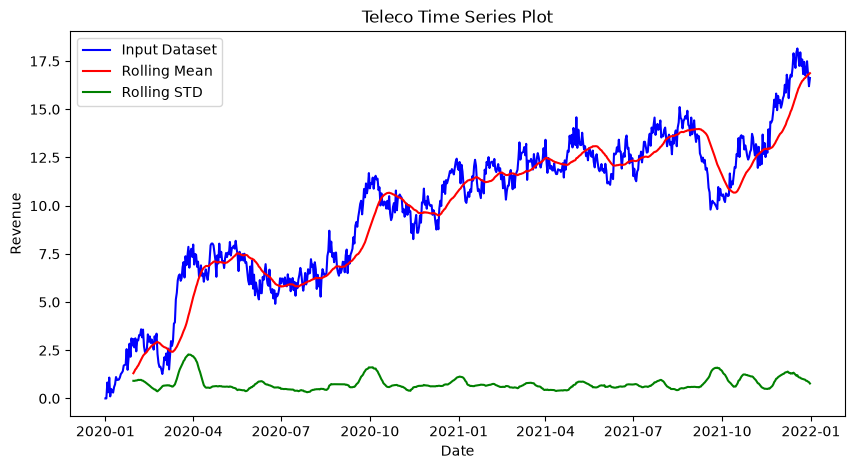

In [3]:
# Calculate rolling average and standard deviation
# One-month (thirty-day) window
roll_mean = teleco_timeseries.rolling(window=30).mean()
roll_std = teleco_timeseries.rolling(window=30).std()

# Use matplotlib to plot the time series
plt.figure(figsize=[10,5])
orig = plt.plot(teleco_timeseries,color='Blue',label="Input Dataset")
mean = plt.plot(roll_mean,color='Red',label='Rolling Mean')
std = plt.plot(roll_std,color='Green',label='Rolling STD')
plt.title('Teleco Time Series Plot')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.legend(loc='best')
plt.show()

The line graph of the teleco time series has been provided above; this shows two years of revenue for the telecommunications company, beginning in January 2020 and ending January 2022. The graph also plots the rolling mean and standard deviation of the data, displayed as red and green lines, respectively. This line graph shows a clear upward trend over time; as such, the data cannot be said to be stationary. 

#### C2. Time Step Formating

The dataset contains two columns: a datetime index representing an individual day, and a revenue column showing revenue for that day. The time stepping is therefore measured in days, without any gaps in measurement. The dataset represents daily revenue over a two-year period, from January 2020 through January 2022.

#### C3. Stationarity

The below code performs, among other things, an Augmented Dickey-Fuller test to determine the stationarity of the data. A p-value greater than or equal to 0.05 indicates that the data is not stationary.

In [4]:
# Check timeseries to see if its stationary using Augmented Dickey-Fuller
# P-value >= 0.05 indicates non-stationary

def ad_test(dataset):
    dftest = adfuller(dataset, autolag='AIC')
    print("1. ADF/Test Statistic:", dftest[0])
    print("2. P-Value:", dftest[1])
    print("3. Num of Lags:", dftest[2])
    print("4. Num of Obs Used for ADF Regression and Critical Values Calc:", dftest[3])
    print("5. Critical Values:")
    for key, val in dftest[4].items():
        print("\t",key,": ",val)

ad_test(teleco_timeseries)

1. ADF/Test Statistic:

 -1.9246121573101813
2. P-Value: 0.32057281507939756
3. Num of Lags: 1
4. Num of Obs Used for ADF Regression and Critical Values Calc: 729
5. Critical Values:
	 1% :  -3.4393520240470554
	 5% :  -2.8655128165959236
	 10% :  -2.5688855736949163


As shown above, the p-value from the ADFuller test is 0.3206, indicating that the data is not stationary. Additional steps will need to be taken to make the data stationary so that the ARIMA model can be applied.

The code below uses differencing to make the data stationary. Differencing is the process whereby the previous observation is subtracted from the current observation; this helps to remove trends and seasonality from the data.

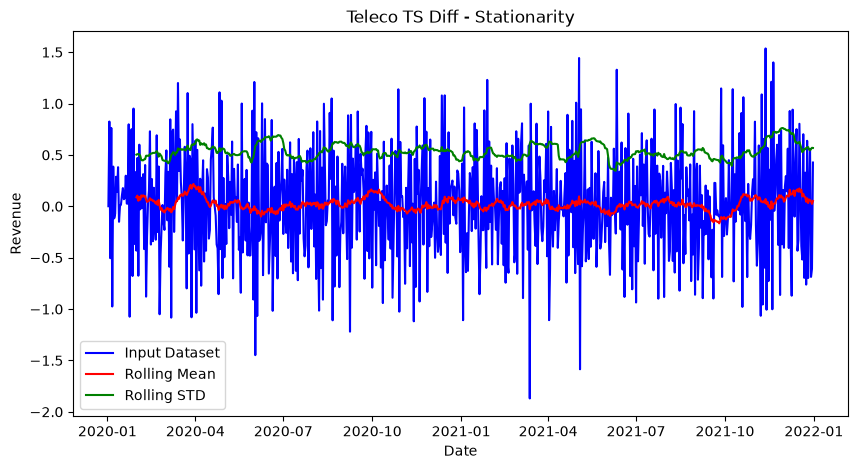

In [5]:
# Use differencing to make time series stationary

teleco_ts_diff = teleco_timeseries['Revenue'].diff().dropna()

# Calculate rolling average and standard deviation
roll_mean_diff = teleco_ts_diff.rolling(window=30).mean()
roll_std_diff = teleco_ts_diff.rolling(window=30).std()

# Use matplotlib to plot the time series
plt.figure(figsize=[10,5])
orig_diff = plt.plot(teleco_ts_diff,color='Blue',label="Input Dataset")
mean_diff = plt.plot(roll_mean_diff,color='Red',label='Rolling Mean')
std_diff = plt.plot(roll_std_diff,color='Green',label='Rolling STD')
plt.title('Teleco TS Diff - Stationarity')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.legend(loc='best')
plt.show()
#teleco_ts_diff.plot()

The line graph above shows relatively flat rolling mean and standard deviation, which implies that the data has successfully been made stationary. To verify this, the code below executes another Augmented Dickey-Fuller test.

In [6]:
# Verify stationarity
def ad_test(dataset):
    dftest = adfuller(dataset, autolag='AIC')
    print("1. ADF:", dftest[0])
    print("2. P-Value:", dftest[1])
    print("3. Num of Lags:", dftest[2])
    print("4. Num of Obs Used for ADF Regression and Critical Values Calc:", dftest[3])
    print("5. Critical Values:")
    for key, val in dftest[4].items():
        print("\t",key,": ",val)

ad_test(teleco_ts_diff)

1. ADF: -44.874527193875984
2. P-Value: 0.0
3. Num of Lags: 0
4. Num of Obs Used for ADF Regression and Critical Values Calc: 729
5. Critical Values:
	 1% :  -3.4393520240470554
	 5% :  -2.8655128165959236
	 10% :  -2.5688855736949163


The Augmented Dickey-Fuller test shows a p-value of 0.0, and the absolute values of all critical values are below the ADF test statistic. This shows that the data has been made stationary.

#### C4. Steps to Prepare the Data

The initial steps to import and inspect the data were performed above, in section C1. This includes importing the .csv file, inspecting the data for missing or null values, and correctly formatting the date column as DateTime and setting it to the index.

The code below creates training and testing datasets by splitting up the input timeseries dataset. The test dataset is configured to hold 25% of all observations (180 days) worth of data; all other observations are assigned to the training dataset.

In [7]:
# Split training and test data
train = teleco_timeseries.iloc[:-180] #assign all other data to train
test = teleco_timeseries.iloc[-180:] #set aside ~25% of the dataset for test
print(train.shape, test.shape)

(551, 1) (180, 1)


#### C5. Prepared Data Set

Provide a copy of the cleaned data set.

In [8]:
teleco_timeseries.to_csv('clean_teleco_timeseries.csv', index=False)
teleco_ts_diff.to_csv('teleco_timeseries_diffed.csv', index=False)

Copies of both the cleaned teleco timeseries dataset, and the diff'd teleco timeseries dataset, have been provided alongside this submission.

### Part IV: Model Identification and Analysis

#### D1. Report Findings and Visualizations

<Axes: title={'center': 'Teleco Timeseries - Seasonality'}, xlabel='Date'>

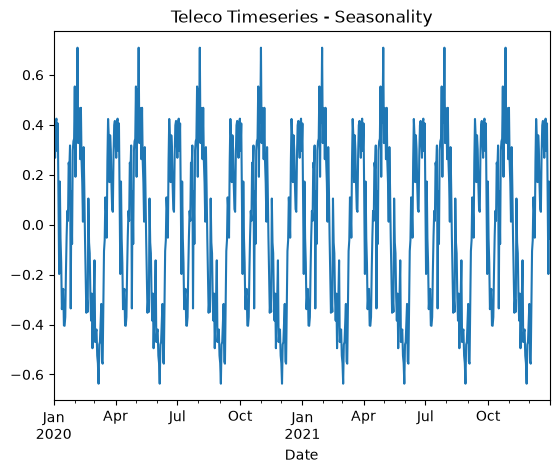

In [9]:
decomp = seasonal_decompose(teleco_timeseries['Revenue'], period=90)
plt.title("Teleco Timeseries - Seasonality")
decomp.seasonal.plot()

A plot of the seasonality of the teleco timeseries dataset cna be seen above. There is a clear, repeating pattern, indicating that there is seasonality in the data.

<Axes: title={'center': 'Teleco Timeseries - Trend'}, xlabel='Date'>

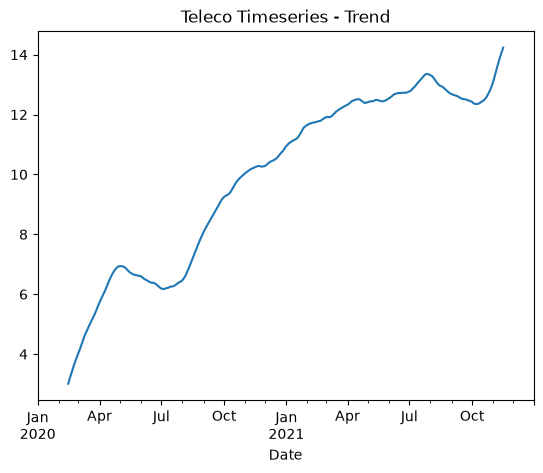

In [10]:
plt.title("Teleco Timeseries - Trend")
decomp.trend.plot()

A trend plot for the teleco timeseries dataset is printed above. There is a clear, upward trend over time.

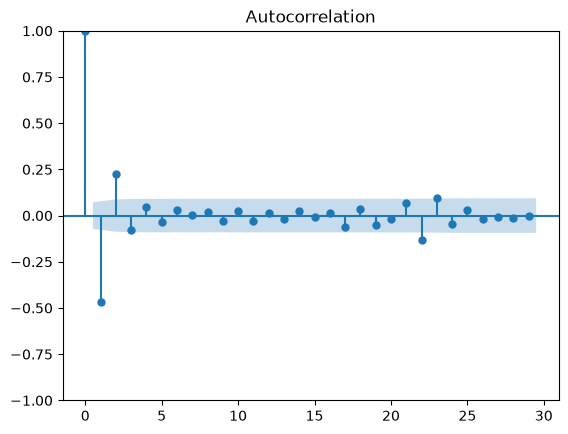

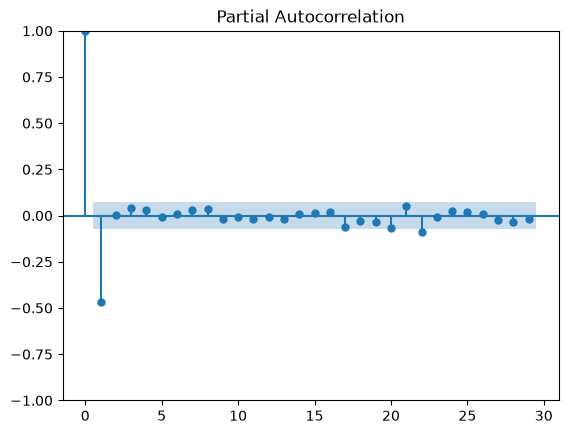

In [11]:
acf_plot = plot_acf(teleco_ts_diff)

pacf_plot = plot_pacf(teleco_ts_diff)

The autocorrelation (ACF) and partial autocorrelation (PACF) graphs for the differentiated teleco timeseries datasets are printed above.

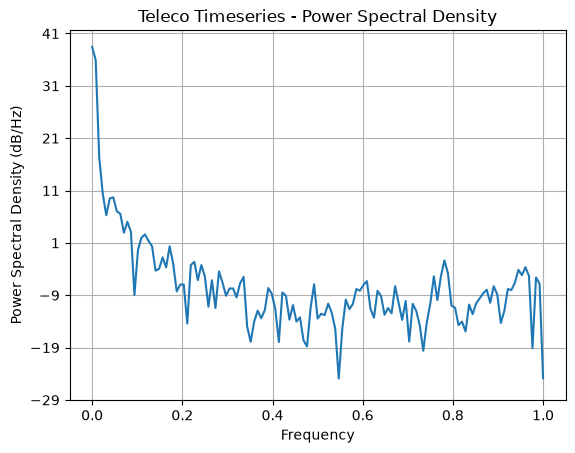

In [12]:
plt.title("Teleco Timeseries - Power Spectral Density")
plt.psd(x=teleco_timeseries['Revenue']);

The power spectral density plot for the teleco timeseries dataset is printed above. 

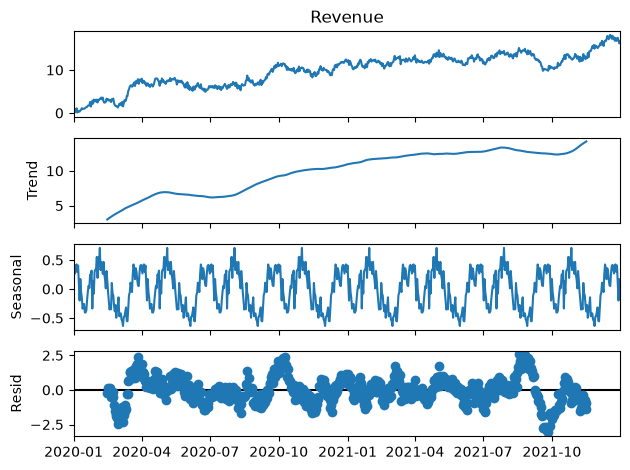

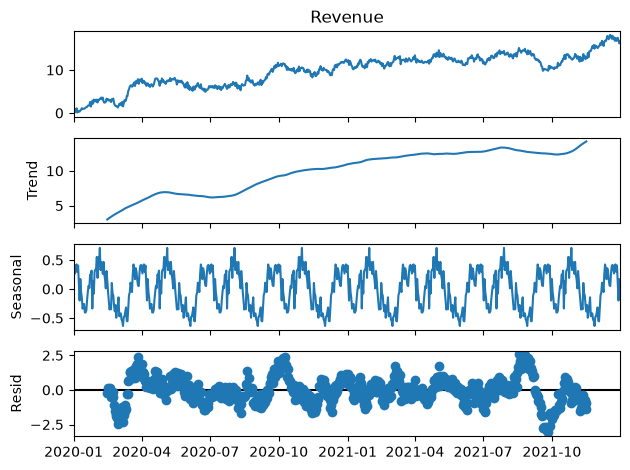

In [13]:
decomp.plot()

The decomposed time series can be seen above. This includes a plot of the trend, seasonality, and residuals. As discussed previously, there is a clear positive trend over time. Additionally, seasonality clearly exists in this data, as we can see repeating pattern reflected in the seasonal graph. The residuals do not show a clear pattern or trend.

<Axes: title={'center': 'Teleco Timeseries - Residual Plot'}, xlabel='Date'>

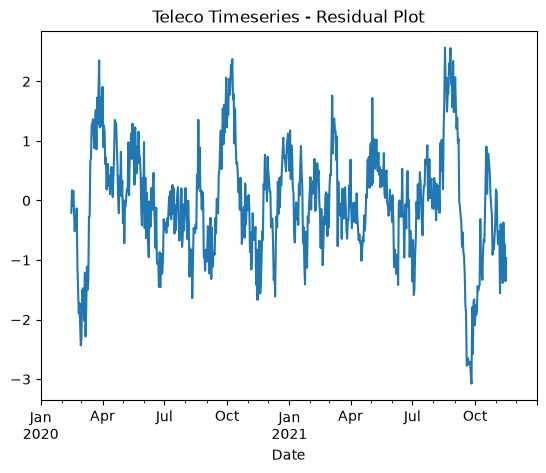

In [14]:
plt.title("Teleco Timeseries - Residual Plot")
decomp.resid.plot()

The residuals for the decomposed timeseries have been plotted above. There appears to be no pattern or trend in the residuals.

#### D2. ARIMA Model

To identify an appropriate ARIMA model for this analysis, I'll make use of the auto_arima function from the pmdarima library. This function will perform a stepwise search to find the best ARIMA model to apply to this data, using the Akaike Information Criterion (AIC) to evaluate the models against one another. AIC is best used as a relative comparison for models applied to the same data.

In [15]:
# Auto-ARIMA
from pmdarima import auto_arima
stepwise_fit=auto_arima(train,trace=True)
stepwise_fit.summary()

Performing stepwise search to minimize aic


 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=736.854, Time=0.28 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=866.751, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=733.431, Time=0.04 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=761.171, Time=0.06 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=865.571, Time=0.01 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=735.391, Time=0.05 sec


 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=735.399, Time=0.06 sec


 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=736.785, Time=0.21 sec
 ARIMA(1,1,0)(0,0,0)[0]             : AIC=733.700, Time=0.02 sec

Best model:  ARIMA(1,1,0)(0,0,0)[0] intercept
Total fit time: 0.785 seconds


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                  551
Model:               SARIMAX(1, 1, 0)   Log Likelihood                -363.715
Date:                Mon, 16 Nov 2026   AIC                            733.431
Time:                        13:35:45   BIC                            746.361
Sample:                    01-01-2020   HQIC                           738.484
                         - 07-04-2021                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0302      0.020      1.500      0.134      -0.009       0.070
ar.L1         -0.4666      0.037    -12.556      0.000      -0.539      -0.394
sigma2         0.2196      0.014     15.710      0.000       0.192       0.247
===================================================================================
Ljung-Box (L1) (Q):                   0.01   Jarque-Bera (JB):                 1.19
Prob(Q):                              0.94   Prob(JB):                         0.55
Heteroskedasticity (H):               1.01   Skew:                            -0.06
Prob(H) (two-sided):                  0.97   Kurtosis:                         2.80
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

The output of the auto_arima function above found that a SARIMAX(1,1,0) model is appropriate for this data.

In [16]:
# Build SARIMAX model using results from auto-ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(train, order=(1,1,0),seasonal_order=(0,1,1,90))
sarimax_results = model.fit()
sarimax_results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                      SARIMAX Results                                       
============================================================================================
Dep. Variable:                              Revenue   No. Observations:                  551
Model:             SARIMAX(1, 1, 0)x(0, 1, [1], 90)   Log Likelihood                -374.991
Date:                              Mon, 16 Nov 2026   AIC                            755.981
Time:                                      13:36:13   BIC                            768.375
Sample:                                  01-01-2020   HQIC                           760.862
                                       - 07-04-2021                                         
Covariance Type:                                opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5059      0.041    -12.295      0.000      -0.587      -0.425
ma.S.L90      -0.8295      0.133     -6.241      0.000      -1.090      -0.569
sigma2         0.2429      0.031      7.869      0.000       0.182       0.303
===================================================================================
Ljung-Box (L1) (Q):                   0.39   Jarque-Bera (JB):                 2.34
Prob(Q):                              0.53   Prob(JB):                         0.31
Heteroskedasticity (H):               1.05   Skew:                            -0.17
Prob(H) (two-sided):                  0.74   Kurtosis:                         3.09
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

#### D3. Forecasting Using ARIMA Model

A forecast using the SARIMAX model from D2 has been performed below.

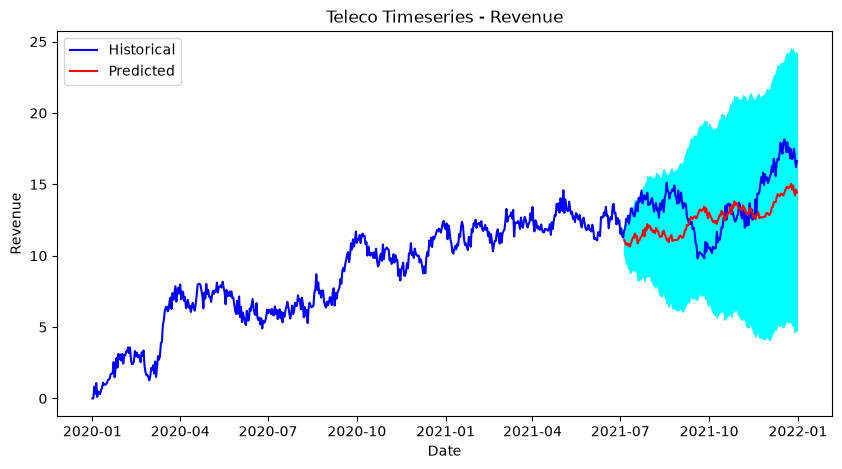

In [17]:
forecast_steps = 180
forecast = sarimax_results.forecast(steps=forecast_steps)

diff_fcast = sarimax_results.get_forecast(steps=forecast_steps)
conf_intervals = diff_fcast.conf_int()
lower_limits = conf_intervals.loc[:,'lower Revenue']
upper_limits = conf_intervals.loc[:,'upper Revenue']

plt.figure(figsize=[10,5])
plt.title('Teleco Timeseries - Revenue')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.plot(teleco_timeseries,label='Historical', color='blue')
plt.plot(forecast, label='Predicted', color='red')
plt.fill_between(conf_intervals.index, conf_intervals['lower Revenue'], conf_intervals['upper Revenue'], color = 'cyan')
plt.legend()
plt.show()

2021-07-05    11.096805
2021-07-06    10.931231
2021-07-07    10.771481
2021-07-08    10.861029
2021-07-09    10.714254
                ...    
2021-12-27    14.920422
2021-12-28    14.499141
2021-12-29    14.229322
2021-12-30    14.625721
2021-12-31    14.430583
Freq: D, Name: predicted_mean, Length: 180, dtype: float64


<Axes: xlabel='Date'>

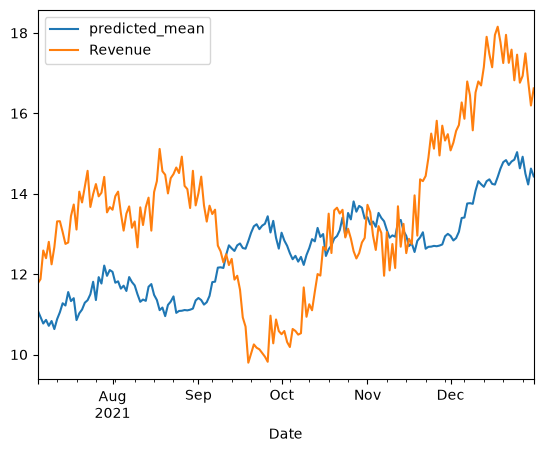

In [18]:
start = len(train)
end = len(train)+len(test)-1
pred=sarimax_results.predict(start=start,end=end)
print(pred)

pred.index=teleco_timeseries.index[start:end+1]


pred.plot(legend=True)
test['Revenue'].plot(legend=True)

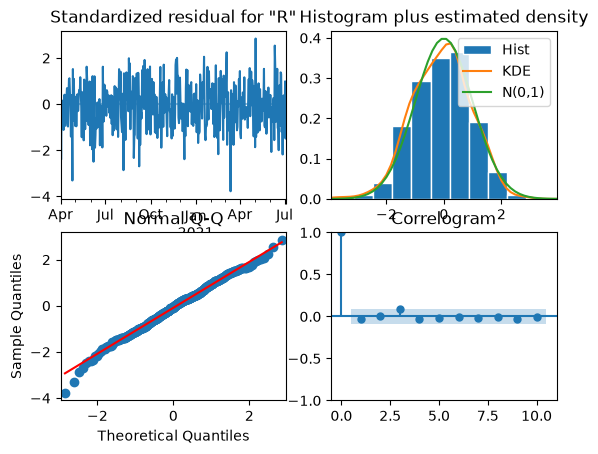

In [19]:
sarimax_results.plot_diagnostics();

The diagnostics plot for the SARIMAX model, including standardized residual, histogram with KDE curve, normal Q-Q plot, and correlogram, has been provided above. A more detailed analysis of these diagnostics will be explored below.

#### D4. Output and Calculations

All output and calculations relevant to the implementation of this time series forecasting model have been provided above.

#### D5. Code

### Part V: Data Summary and Implications

#### E1. Results

The time series model was selected using the auto_arima function from the pmdarima library, which identified SARIMAX(1,1,0) as being the most appropriate model for this use case. Auto_arima determined this by performing stepwise evaluations of various SARIMAX models, and selecting the one with the lowest AIC score.

The forecast interval for this analysis is 180 days, which represents roughly 25% of the datapoints of the original dataset. Personally, I would not recommend exceeding this interval as the confidence interval significantly widens over time, meaning that forecasts become less accurate further out. The interval used here maintains a reasonable CI - increaisng the forecast interval would result in a less accurate, and therefore less useful, analysis.

The diagnostics plots for this model have been reprinted below:

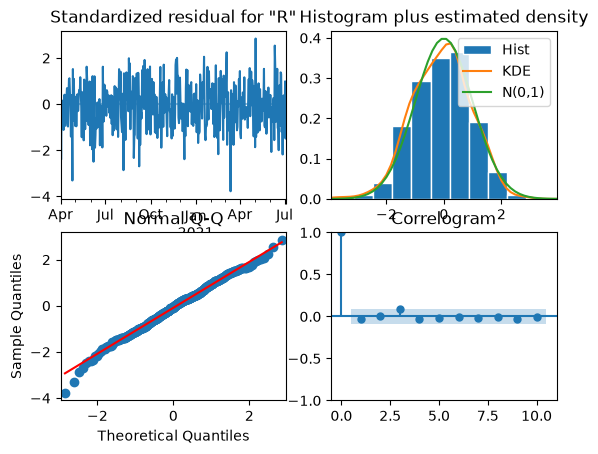

In [20]:
sarimax_results.plot_diagnostics();

Evaluating these plots clockwise, starting at the upper-left, we see that the model shows desirable characteristics:
1. The standardized residual plot shows no obvious trend or repeating pattern;
2. The Kernel Density Estimate (KDE) curve generally matches the histogram;
3. The correlogram shows that correlations greater than lag zero are insignificant;
4. The Normal Q-Q plot shows that the majority of datapoints fall along the red line.

In [21]:
from sklearn.metrics import mean_squared_error
from math import sqrt
rmse = sqrt(mean_squared_error(pred,test['Revenue']))
print(rmse)

2.1526363858608932


Above, I've calculated the root mean squared error (RMSE). Lower values for the RMSE indicate better models, as this reflects the average distance between the predicted and observed values. The RMSE for this model is 2.15, which indicates a strong model. This metric can be used when comparing and evaluating this model's performance against other models trained on the same data.

#### E2. Annotated Visualization

The annoted visualization of the forecast of the final model has been included below:

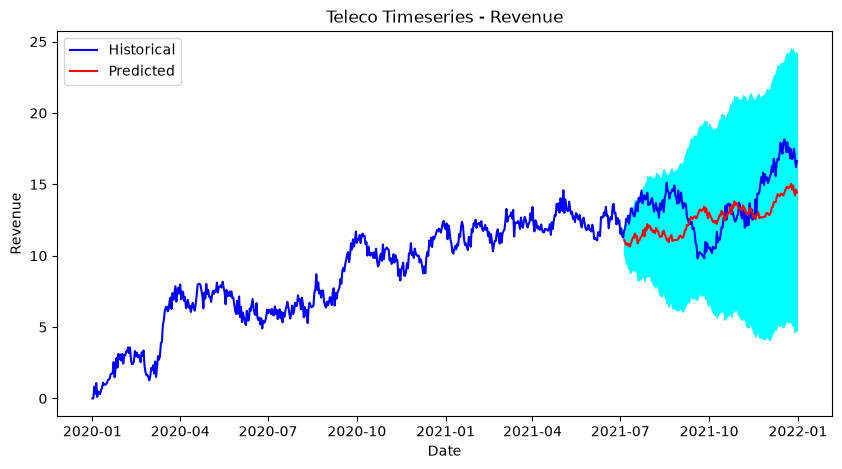

In [22]:
plt.figure(figsize=[10,5])
plt.title('Teleco Timeseries - Revenue')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.plot(teleco_timeseries,label='Historical', color='blue')
plt.plot(forecast, label='Predicted', color='red')
plt.fill_between(conf_intervals.index, conf_intervals['lower Revenue'], conf_intervals['upper Revenue'], color = 'cyan')
plt.legend()
plt.show()

#### E3. Recommendation

Overall, I am pleased with the forecast generated by this model. The model performs well overall, with an RMSE of 2.15. Frankly this has exceeded my expectations. The forecast is generally, but not perfectly, accurate for forecast periods of around 180 days. My recommendation to the telecommunications company would be to deploy this model into production for use as a generalized forecast model for forecasting revenue within this 180-day time horizon; however, steps should be taken to ensure that all stakeholders understand this model is a forecast, not a perfect predictor of revenue. 

### Part VI: Attachments

#### F. Reporting

As required by part F of the rubric, this analysis was performed in a Jupyter notebook environment.

#### G. Sources of Third-Party Code

GeeksForGeeks. *Time Series Modeling with Statsmodels.* July 23, 2025. https://www.geeksforgeeks.org/deep-learning/time-series-modeling-with-statsmodels/

Pandas Documentation. *pandas.to_datetime*. Accessed December 28, 2025. https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.to_datetime.html

Python Standard Library Documentation. *datetime — Basic date and time types* Accessed December 28, 2025. https://docs.python.org/3/library/datetime.html


#### H. Sources

Binhuraib, Taha. *An Introduction to Time Series Analysis with ARIMA.* Towards Data Science. March 15, 2021. https://towardsdatascience.com/an-introduction-to-time-series-analysis-with-arima-a8b9c9a961fb/

GeeksForGeeks. *Time Series Analysis and Forecasting.* October 24, 2025. https://www.geeksforgeeks.org/machine-learning/time-series-analysis-and-forecasting/

StatisticsSolutions. *The Stationary Data Assumption in Time Series Analysis*. Accessed January 26, 2025. https://www.statisticssolutions.com/stationary-data-assumption-in-time-series-analysis/